# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
# Static PNG output so the charts render on GitHub (needs: pip install -U kaleido)
# For interactive charts while working locally, comment this line out
import plotly.io as pio
pio.renderers.default = 'png'

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


Region
Asia             35045.1
Europe           15387.0
Latin America    12376.0
North America    11131.0
Middle East       9671.0
Africa            8620.0
Oceania           8142.0
Name: TWh, dtype: float64


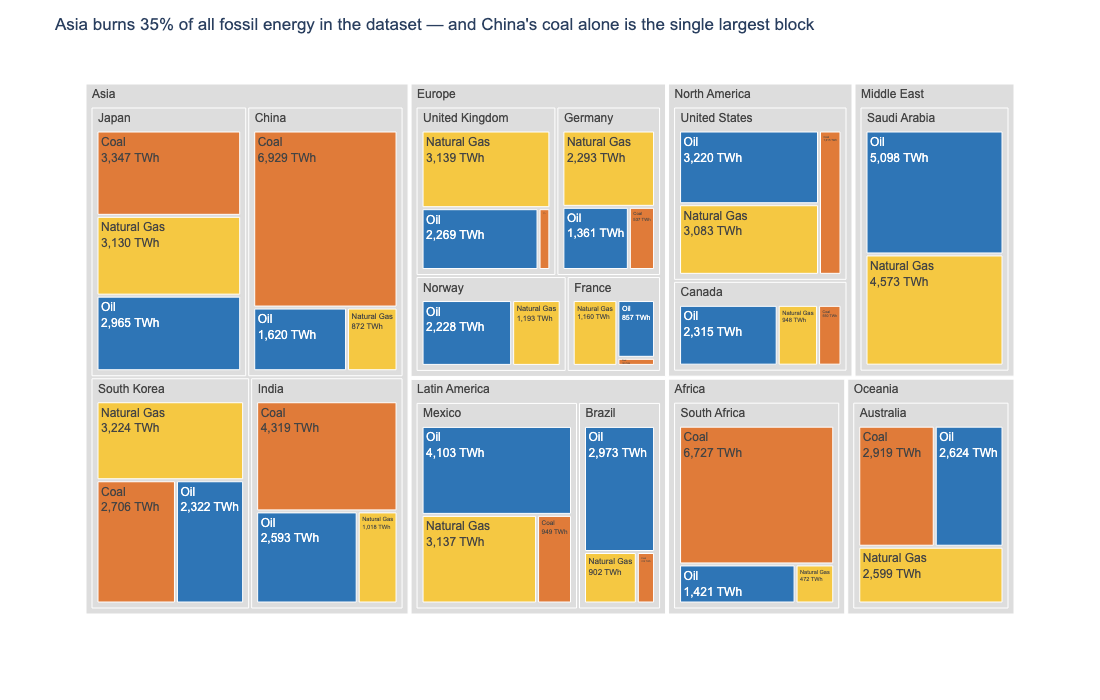

In [2]:
# Task 1

# ── Data prep ─────────────────────────────────────────────────────────────────
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# CVD-safe palette (same three hues as the lecture: orange / blue / yellow)
fossil_colors = {
    'Coal':        '#E07B39',   # orange
    'Oil':         '#2E75B6',   # blue
    'Natural Gas': '#F5C842',   # yellow
}

# Numbers for the insight title
region_twh = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
top_region, top_share = region_twh.index[0], region_twh.iloc[0] / region_twh.sum()
print(region_twh)

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    labels={'TWh': 'Energy (TWh)'},
    height=700, width=1100,
    template='plotly_white',
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh',        # TWh values, no percentages
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)

fig.update_layout(
    title=(f'{top_region} burns {top_share:.0%} of all fossil energy in the dataset — '
           f"and China's coal alone is the single largest block"),
    font=dict(family='Arial', size=12),
)

# Grey out parent nodes (Region and Country) — only the Source leaves keep a palette colour
fig.data[0].marker.colors = [
    c if c in fossil_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

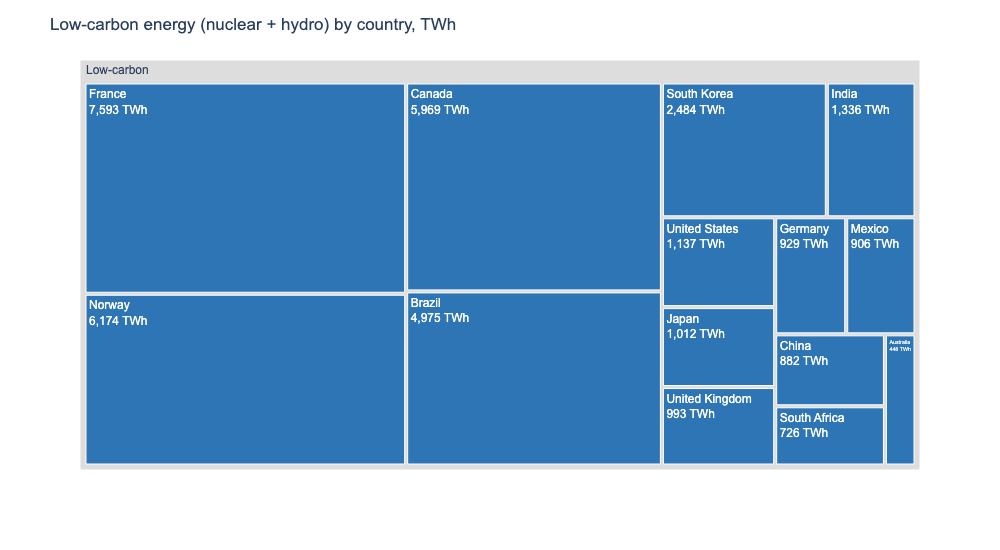

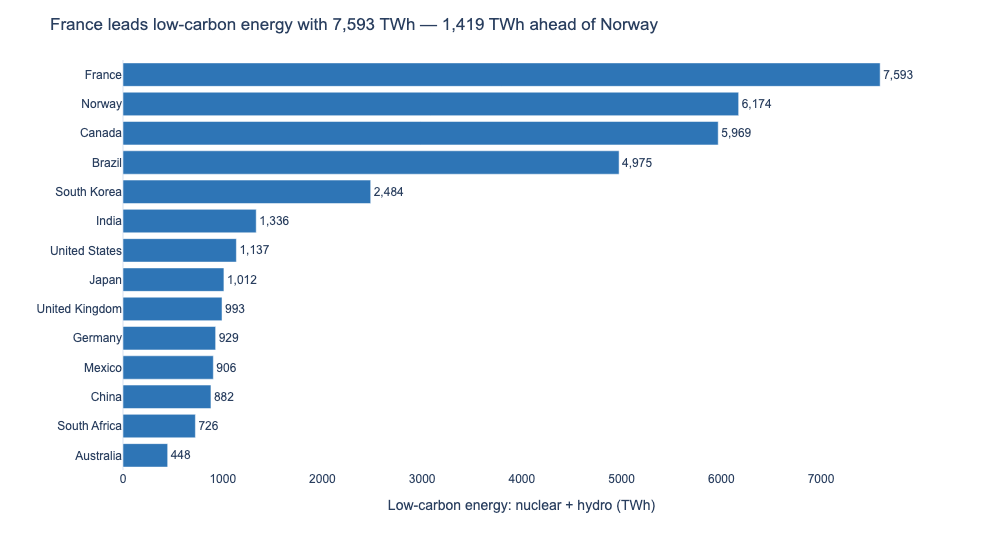

In [3]:
# Task 2 — charts

# ── Data prep ─────────────────────────────────────────────────────────────────
low_carbon = (df.loc[df['Source_Type'] == 'Low-carbon']
                .groupby('Country')['TWh'].sum()
                .reset_index()
                .sort_values('TWh', ascending=False))
low_carbon['All'] = 'Low-carbon'                 # dummy root node for the single-level treemap

BLUE = '#2E75B6'                                 # CVD-safe blue = low-carbon, as in the lecture
leader, runner_up = low_carbon.iloc[0], low_carbon.iloc[1]

# ── Chart A: treemap ──────────────────────────────────────────────────────────
fig = px.treemap(
    low_carbon,
    path=['All', 'Country'],
    values='TWh',
    color_discrete_sequence=[BLUE],
    height=550, width=1000,
    template='plotly_white',
)
fig.update_traces(
    root_color='#DDDDDD',                                   # grey root node
    marker_colors=['#DDDDDD' if p == '' else BLUE for p in fig.data[0].parents],
    texttemplate='%{label}<br>%{value:,.0f} TWh',           # TWh values, no percentages
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)
fig.update_layout(
    title='Low-carbon energy (nuclear + hydro) by country, TWh',
    font=dict(family='Arial', size=12),
)
fig.show()

# ── Chart B: horizontal bar, sorted ───────────────────────────────────────────
fig = px.bar(
    low_carbon,
    x='TWh', y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=[BLUE],
    category_orders={'Country': low_carbon['Country'].tolist()},   # largest at the top
    labels={'TWh': 'Low-carbon energy: nuclear + hydro (TWh)'},
    height=550, width=1000,
    template='plotly_white',
)
fig.update_traces(
    texttemplate='%{x:,.0f}', textposition='outside', cliponaxis=False,
    hovertemplate='<b>%{y}</b><br>%{x:,.0f} TWh<extra></extra>',
)
fig.update_layout(
    title=(f"{leader['Country']} leads low-carbon energy with {leader['TWh']:,.0f} TWh — "
           f"{leader['TWh'] - runner_up['TWh']:,.0f} TWh ahead of {runner_up['Country']}"),
    font=dict(family='Arial', size=12),
    yaxis=dict(title=''),
    xaxis=dict(showgrid=False),
)
fig.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The bar chart. Every bar starts from the same baseline, so the reader compares **lengths**, which the eye judges accurately, and the sorted order makes the ranking readable from top to bottom without checking a single number. The treemap encodes the same values as **areas** of rectangles with different proportions, which are much harder to compare: France, Norway and Canada look roughly alike, and the order of the mid-sized countries can only be worked out by reading the labels. The treemap does show at a glance that four countries make up about 70% of the total, but with a single level it has no hierarchy to reveal — so for a ranking question the bar wins.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

Region
Africa           0.780
Asia             0.494
Oceania          0.359
North America    0.141
Latin America    0.102
Europe           0.058
Middle East      0.000
Name: Share, dtype: float64


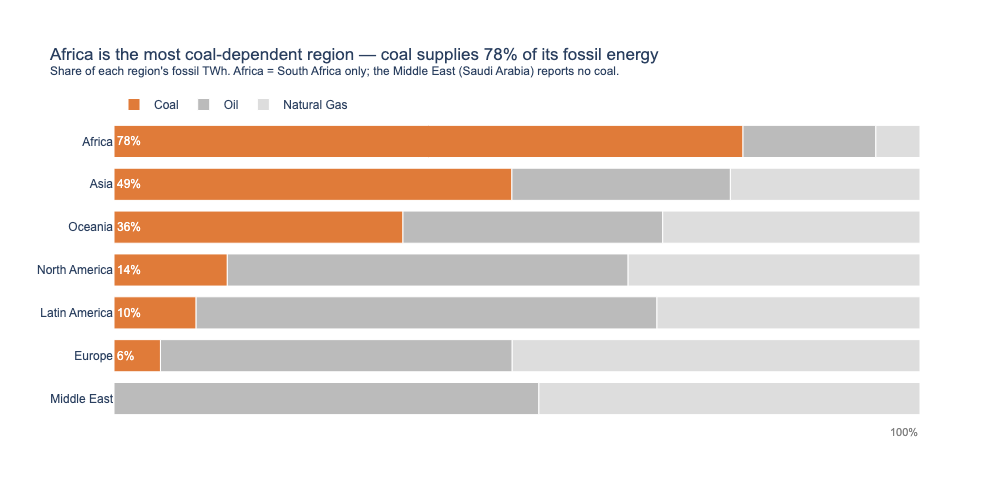

In [4]:
# Task 3

# ── Data prep ─────────────────────────────────────────────────────────────────
mix = df_fossil.groupby(['Region', 'Source'])['TWh'].sum().reset_index()
mix['Share'] = mix['TWh'] / mix.groupby('Region')['TWh'].transform('sum')   # share of the region's fossil total

# Sort regions by coal share, highest at the top (a region without coal counts as 0)
coal_share = (mix.loc[mix['Source'] == 'Coal'].set_index('Region')['Share']
                 .reindex(mix['Region'].unique(), fill_value=0)
                 .sort_values(ascending=False))
region_order = coal_share.index.tolist()
print(coal_share.round(3))

# Percentage labels on the coal segments only
mix['Label'] = np.where(mix['Source'] == 'Coal', mix['Share'].map('{:.0%}'.format), '')

# One accent colour (coal = the same orange as in Task 1); two greys for context
accent_mapping = {
    'Coal':        fossil_colors['Coal'],   # orange accent — the story
    'Oil':         '#BBBBBB',               # mid grey — context
    'Natural Gas': '#DDDDDD',               # light grey — context
}

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.bar(
    mix,
    x='Share', y='Region',
    color='Source',
    text='Label',
    color_discrete_map=accent_mapping,
    category_orders={'Region': region_order,
                     'Source': ['Coal', 'Oil', 'Natural Gas']},    # coal sits on the baseline
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    hover_name='Region',
    hover_data={'Label': False, 'Region': False, 'Share': ':.0%', 'TWh': ':,.0f'},
    height=500, width=1000,
    template='plotly_white',
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(
    textposition='inside', insidetextanchor='start',     # label at the left edge of the coal segment
    textfont=dict(color='white', size=12),
    marker_line_color='white', marker_line_width=1,
)

fig.update_layout(
    title=dict(text=(f'{region_order[0]} is the most coal-dependent region — coal supplies '
                     f'{coal_share.iloc[0]:.0%} of its fossil energy'
                     f'<br><sup>Share of each region\'s fossil TWh. Africa = South Africa only; '
                     f'the Middle East (Saudi Arabia) reports no coal.</sup>')),
    font=dict(family='Arial', size=12),
    bargap=0.25,
    margin=dict(t=120),
    legend=dict(orientation='h', x=0, y=1.1, title=''),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title=''),
)

# Mark the end of the scale — every bar sums to 100%
fig.add_annotation(
    x=1, y=0, xref='x', yref='paper',
    xanchor='right', yanchor='top', yshift=-4,
    text='100%', showarrow=False,
    font=dict(size=11, color='grey'),
)

fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

**Treemap only — "How big is it, and where does it sit?"** Because area encodes absolute TWh, the treemap shows that Asia burns the most fossil energy overall and that China's coal is the largest single block, and it keeps the country level visible inside each region. The stacked bar normalises every region to 100%, so absolute size and the countries disappear: Africa (one country, about 8,600 TWh) gets the same bar length as Asia (about 35,000 TWh).

**Stacked bar only — "Which region relies most on coal, relative to its own fossil use?"** With coal on a common baseline and the regions sorted, the ranking by coal share (Africa 78% > Asia > Oceania > …) can be read directly. In the treemap this is close to impossible: you would have to estimate the ratio of the orange area to each region's total area, and big regions dominate the view regardless of their mix.